The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


c:\Users\Maciej\Documents\GitHub\SemanticPullbacks\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Maciej\Documents\GitHub\SemanticPullbacks\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG11_BN_Weights.IMAGENET1K_V1`. You can also use `weights=VGG11_BN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


tensor(-1., device='cuda:0') tensor(1., device='cuda:0') tensor(-0.1169, device='cuda:0') tensor(0.5580, device='cuda:0')
images.shape = torch.Size([10, 3, 224, 224])
labels = [497, 566, 482, 701, 569, 482, 569, 491, 566, 571]


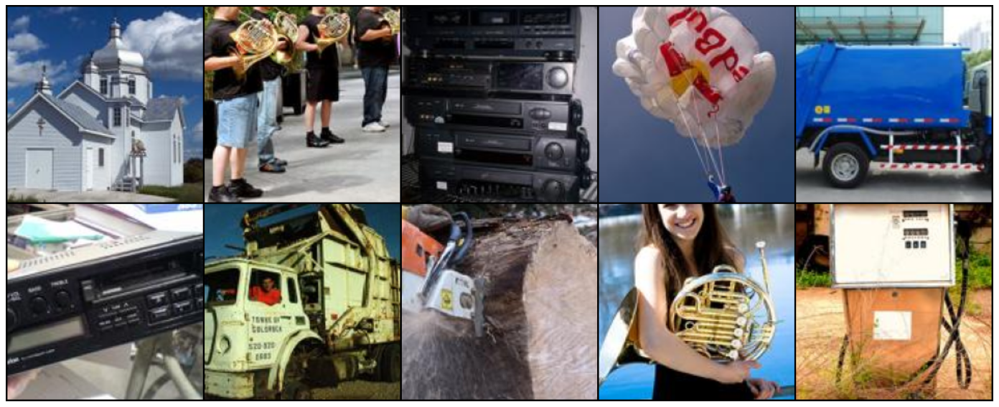

In [87]:
%load_ext autoreload
%autoreload 2
# %matplotlib inline

import os

# to allow deterministic gradients on CUDA
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

while 'notebooks' in os.getcwd():
    os.chdir("../")

# !pwd

import torch
from torch import nn, einsum

# determnistic = True
determnistic = False  # doesn't always work with some layers
torch.use_deterministic_algorithms(determnistic)
torch.backends.cudnn.deterministic = determnistic

import quantus
import gc
import torch.nn.functional as F

from lib.helpers import plot_example_grid
from lib.attributions import GradientAscentDiff, PullbackAscentDiff, \
    quantus_pullback_ascent_diff_explain_func
from lib.setup import setup_notebook
from lib.defaults import get_default_kwargs
from lib.surrogates import LayerNorm2d, PVTAttention, soften_module_inplace_
from lib.evaluator import QuantusEvaluator, default_explainers, default_metrics


batch_size = 10
# model_name = "resnet50"
model_name = "vgg11_bn"
model_source = "torchvision"

# model_name = "pvt_v2_b1"
# model_source = "timm"

seed = 314159
# seed = 31415

device, loader, model = setup_notebook(batch_size=batch_size, model_name=model_name, model_source=model_source, seed=seed)

it = iter(loader)
images, labels = next(it)

x_batch = images.numpy()
y_batch = labels.numpy()
images = images.to(device)
labels = labels.to(device)

n_show = 15

# print(len(loader.dataset))
print(images.min(), images.max(), images.mean(), images.std())
print(f"images.shape = {images.shape}")
print(f"labels = {labels[:n_show].tolist()}")

plot_example_grid(images[:n_show], nrow=min(5, n_show))

In [ ]:

short_titles_map = {
    "Image": "Image",
    "Gradient": "Grad",
    "SoftPullback": "SfP",
    "GradientAscent": "GA",
    "PullbackAscent": "PA",
    "SmoothGrad": "SmoothG",
    "SmoothPullback": "SmoothPb",
    "FusionGrad": "FusionG",
    "FusionPullback": "FusionPb",
    "GradientShap": "GradShap",
    "IntegratedGradients": "IG",
    "DeepLift": "DeepLift",
    "GuidedGradCam": "GG-CAM",
}

In [89]:
# short_titles_map

In [90]:
if model_name.startswith("resnet"):
    gc_layer = model[1].layer4[-1].conv3
elif model_name.startswith("vgg"):
    gc_layer = model[1].avgpool
elif model_name.startswith("pvt"):
    # gc_layer = model[1].stages[-1].blocks[-1].mlp
    gc_layer = None

In [91]:
gc_layer

AdaptiveAvgPool2d(output_size=(7, 7))

In [92]:
temperatures, pga_kwargs_counterfactual, pga_kwargs_grad, pga_kwargs_adv = get_default_kwargs()

# modify the model in-place, but don't change its backward behavior
soften_module_inplace_(model, temperatures=temperatures, standard_backward=True, fill_default_temperatures=True)

gad = GradientAscentDiff(model, **pga_kwargs_counterfactual)
gad_adv = GradientAscentDiff(model, **pga_kwargs_adv)
grad = GradientAscentDiff(model, **pga_kwargs_grad)

pad = PullbackAscentDiff(model, **pga_kwargs_counterfactual)
sp = PullbackAscentDiff(model, **pga_kwargs_grad)

# explainers = default_explainers(["SoftPullback", "DoublePullback", "PullbackAscent", "PullbackAscentBis", "Gradient"])
# explainers = default_explainers()
explainers = default_explainers(list(short_titles_map.keys()), gc_layer = gc_layer, reduce_axes=False)
# metrics = default_metrics(["monotonicity_correlation", "faithfulness_correlation", "faithfulness_estimate", "infidelity"])
metrics = default_metrics(["infidelity"])

In [93]:
# model

In [94]:
# explainers

In [95]:
evaluator = QuantusEvaluator(
    model,
    metrics,
    explainers,
    device=device,
)

In [96]:
evaluator.precompute_attributions(images, labels)

Precomputing attributions for explainer SoftPullback
Explainer SoftPullback took 0.149 seconds.
Precomputing attributions for explainer PullbackAscent
Explainer PullbackAscent took 0.580 seconds.
Precomputing attributions for explainer SmoothPullback


c:\Users\Maciej\Documents\GitHub\SemanticPullbacks\.venv\Lib\site-packages\captum\attr\_core\saliency.py:129: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(inputs_tuple)


Explainer SmoothPullback took 5.736 seconds.
Precomputing attributions for explainer FusionPullback
Explainer FusionPullback took 12.185 seconds.
Precomputing attributions for explainer Gradient
Explainer Gradient took 0.075 seconds.
Precomputing attributions for explainer GradientAscent
Explainer GradientAscent took 0.334 seconds.
Precomputing attributions for explainer SmoothGrad
Explainer SmoothGrad took 3.331 seconds.
Precomputing attributions for explainer FusionGrad
Explainer FusionGrad took 7.367 seconds.
Precomputing attributions for explainer GradientShap
Explainer GradientShap took 0.501 seconds.
Precomputing attributions for explainer IntegratedGradients
Explainer IntegratedGradients took 18.804 seconds.
Precomputing attributions for explainer DeepLift
Explainer DeepLift took 0.172 seconds.


c:\Users\Maciej\Documents\GitHub\SemanticPullbacks\.venv\Lib\site-packages\captum\log\dummy_log.py:39: UserWarning: Setting forward, backward hooks and attributes on non-linear
               activations. The hooks and attributes will be removed
            after the attribution is finished
  return func(*args, **kwargs)


Precomputing attributions for explainer GuidedGradCam
Explainer GuidedGradCam took 0.125 seconds.


c:\Users\Maciej\Documents\GitHub\SemanticPullbacks\.venv\Lib\site-packages\captum\attr\_core\guided_backprop_deconvnet.py:66: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


In [97]:
attrs_raw = {name: torch.as_tensor(attr).expand(-1, 3, -1, -1) for name, attr in evaluator.attributions.items() if name in short_titles_map}
attrs_dot = {name: a * images.to(a.device) for name, a in attrs_raw.items()}

hadamard = True
# hadamard = False

if hadamard:
    attrs = attrs_dot
else:
    attrs = attrs_raw
# list(attrs.values())[0].shape, images.shape

In [98]:
from lib.helpers import as_cmap_rgb
mode = "mean"
# mode = "norm"
# mode = "abs_mean"
cmap = "seismic"
# cmap = "gray"
# cmap = "inferno"
# normalise = False
normalise = True

def apply_cmap(batch):
    return as_cmap_rgb(batch, cmap_name=cmap, mode=mode, normalise=normalise)

attrs_cmap = {name: apply_cmap(attr) for name, attr in attrs.items()}

In [99]:
# list(attrs_cmap.keys())

In [100]:
titles = ["Image"] + list(attrs.keys())
titles = [short_titles_map.get(t, t) for t in titles]
# titles

In [101]:
from lib.helpers import interleave_batches_columns

n_row = batch_size
show_cmap = [images.cpu()] + list(attrs_cmap.values())
show_cmap = interleave_batches_columns(show_cmap, n_row)
show_cmap.shape

torch.Size([130, 3, 224, 224])

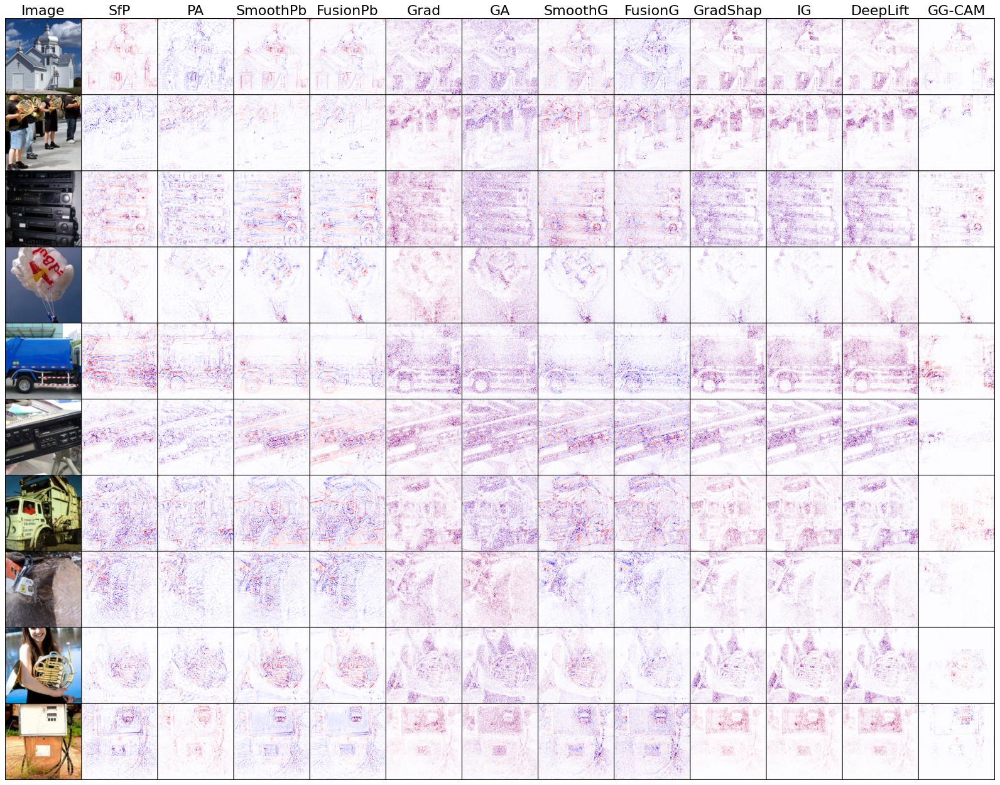

In [102]:
plot_example_grid(show_cmap, nrow=len(attrs_cmap) + 1, dpi=80, fontsize=20, column_titles=titles, save_path=f"media/comparison/comparison_{model_name}_{n_row}{'_hadamard' if hadamard else ''}.jpg")

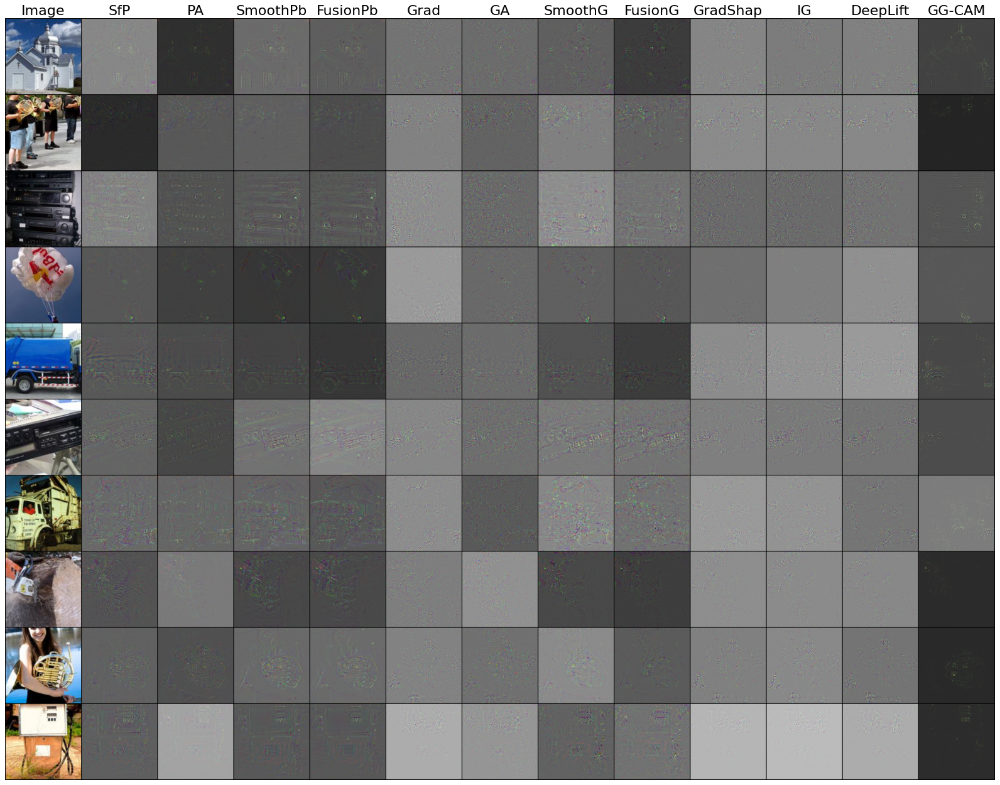

In [103]:
n_row = batch_size
show = [images.cpu()] + list(attrs.values())
show = interleave_batches_columns(show, n_row)
show.shape

plot_example_grid(show, nrow=len(attrs_cmap) + 1, dpi=80, fontsize=20, column_titles=titles, save_path=f"media/comparison/comparison_{model_name}_{n_row}_raw{'_hadamard' if hadamard else ''}.jpg")

In [322]:
# from lib.helpers import interleave_batches

# n_row = batch_size
# show_cmap = [images.cpu()] + list(attrs_cmap.values())
# show_cmap = interleave_batches(show_cmap, n_row)
# show_cmap.shape

In [216]:
# plot_example_grid(show_cmap, nrow=n_row, heatmap=False, dpi=80, fontsize=22, row_titles=titles, save_path=f"media/comparison/comparison_{model_name}_{mode}_{cmap}_normalise_{normalise}.jpg")

In [217]:
# from lib.helpers import interleave_batches

# n_row = batch_size
# show = [images.cpu()] + list(attrs.values())
# show = interleave_batches(show, n_row)
# show.shape

# plot_example_grid(show, nrow=n_row, heatmap=False, dpi=80, row_titles=titles, fontsize=22, save_path=f"media/comparison/comparison_{model_name}_raw.jpg")